# Fraud Detection — Card Transactions

The fraud prevention team reviews suspicious transactions mostly by hand. As volume grows, this creates two risks: **fraud that slips through** and **legitimate customers blocked by mistake**.

This notebook explores the 2025 labelled history, builds a model to classify transactions as fraudulent or not, and classifies January 2026.

1. Data and quality
2. Where fraud happens
3. What drives fraud inside the risk windows
4. What changes over time
5. Exploration takeaways
6. Validation by time
7. Models, from simplest to most complex
8. Decision in three bands
9. Explainability
10. Impact in numbers

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

DATA = Path("../data")
OUTPUTS = Path("../outputs")
OUTPUTS.mkdir(exist_ok=True)

TARGET = "flag_fraude"
FRAUD_COLOR = "#c0392b"
LEGIT_COLOR = "#2e86c1"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data and quality

In [2]:
def load(name):
    df = pd.read_csv(DATA / name, parse_dates=["datahora_transacao"])
    df["hour"] = df["datahora_transacao"].dt.hour
    df["month"] = df["datahora_transacao"].dt.month
    return df


history = load("transacoes_historico_2025.csv")
january = load("transacoes_jan2026.csv")
history[TARGET] = history[TARGET].astype(int)

print(f"History: {len(history):,} rows, {history['datahora_transacao'].min():%Y-%m-%d} to {history['datahora_transacao'].max():%Y-%m-%d}")
print(f"January 2026: {len(january):,} rows")
print(f"Fraud rate: {history[TARGET].mean():.2%} ({history[TARGET].sum():,} frauds)")
print(f"Missing values: {history.isna().sum().sum()} | Duplicated rows: {history.duplicated().sum()}")

History: 523,525 rows, 2025-01-01 to 2025-12-31
January 2026: 44,451 rows
Fraud rate: 3.91% (20,485 frauds)


Missing values: 0 | Duplicated rows: 0


No missing values and no duplicates. With 3.9% fraud, a model that always says "legitimate" is 96% accurate and useless, so **accuracy is not the metric**: we will look at precision, recall and the precision-recall curve.

In [3]:
history.nunique().sort_values().to_frame("unique values")

,unique values
flag_fraude,2
is_new_device,2
valor_categoria,3
device_type,3
cidade_regiao,3
turno,4
tipo_estabelecimento,6
cidade,7
nome_estabelecimento,10
month,12


Several columns are derived from others, so they add no information:

In [4]:
def is_function_of(df, source, derived):
    return df.groupby(source)[derived].nunique().max() == 1


redundant = {
    "turno ← hour": is_function_of(history, "hour", "turno"),
    "cidade_regiao ← cidade": is_function_of(history, "cidade", "cidade_regiao"),
    "tipo_estabelecimento ← nome_estabelecimento": is_function_of(history, "nome_estabelecimento", "tipo_estabelecimento"),
    "valor_categoria ← valor_transacao": is_function_of(history, "valor_transacao", "valor_categoria"),
}
pd.Series(redundant, name="fully determined")

turno ← hour                                   True
cidade_regiao ← cidade                         True
tipo_estabelecimento ← nome_estabelecimento    True
valor_categoria ← valor_transacao              True
Name: fully determined, dtype: bool

And some columns carry no signal. The AUC of a single column measures how well it alone ranks frauds above legitimate transactions: 0.5 is a coin flip.

In [5]:
def single_column_auc(df, column):
    auc = roc_auc_score(df[TARGET], df[column])
    return max(auc, 1 - auc)


signal = pd.Series({col: single_column_auc(history, col) for col in ["score_interno", "temperatura_celsius", "valor_transacao", "is_new_device"]})
signal.sort_values(ascending=False).to_frame("AUC alone")

,AUC alone
is_new_device,0.6982
valor_transacao,0.5301
temperatura_celsius,0.5176
score_interno,0.5011


In [6]:
print(f"codigo_postal: {history['codigo_postal'].nunique():,} values for {len(history):,} rows")
print(f"nome_cliente: {history['nome_cliente'].nunique():,} clients, about {len(history) / history['nome_cliente'].nunique():.0f} transactions each")

codigo_postal: 521,905 values for 523,525 rows
nome_cliente: 26,214 clients, about 20 transactions each


- **`score_interno` does not separate fraud (AUC 0.50).** This is a finding for the business: the internal score in use today behaves like a coin flip on this data.
- **`temperatura_celsius`** is noise, and **`codigo_postal`** is almost unique per row, so it works as an identifier, not a feature.
- `is_new_device` alone already reaches AUC 0.70.

## 2. Where fraud happens

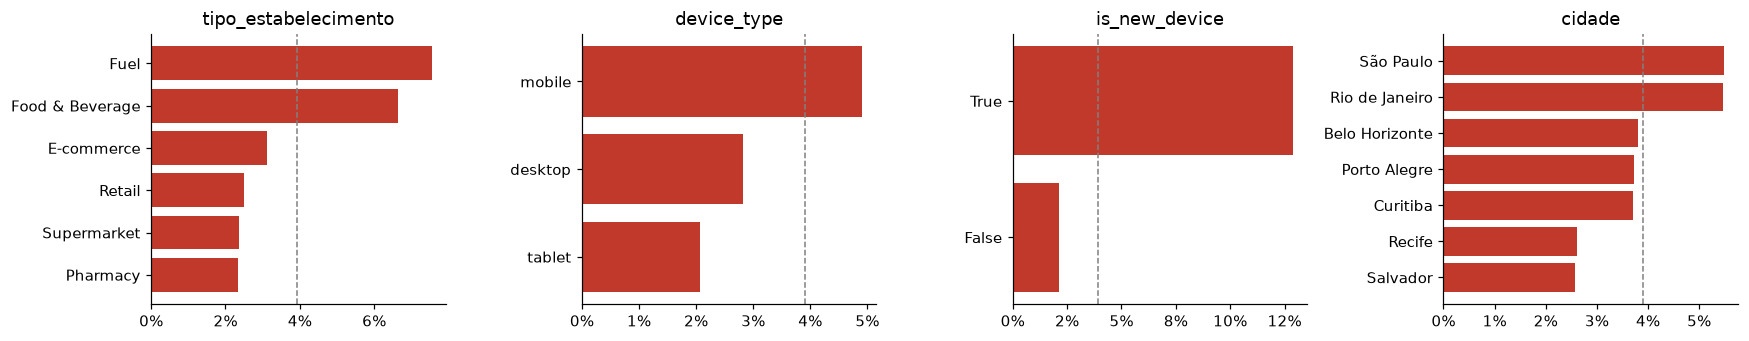

In [7]:
def fraud_rate_bars(df, columns):
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 3.2))
    for ax, column in zip(axes, columns):
        rates = df.groupby(column)[TARGET].mean().sort_values()
        ax.barh(rates.index.astype(str), rates.values, color=FRAUD_COLOR)
        ax.axvline(df[TARGET].mean(), color="grey", linestyle="--", linewidth=1)
        ax.set_title(column)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    fig.tight_layout()
    return fig


fraud_rate_bars(history, ["tipo_estabelecimento", "device_type", "is_new_device", "cidade"]);

Fuel and food stand out, and so do mobile, new devices and São Paulo / Rio de Janeiro. The strongest pattern, though, appears only when we cross **hour** with **merchant type**:

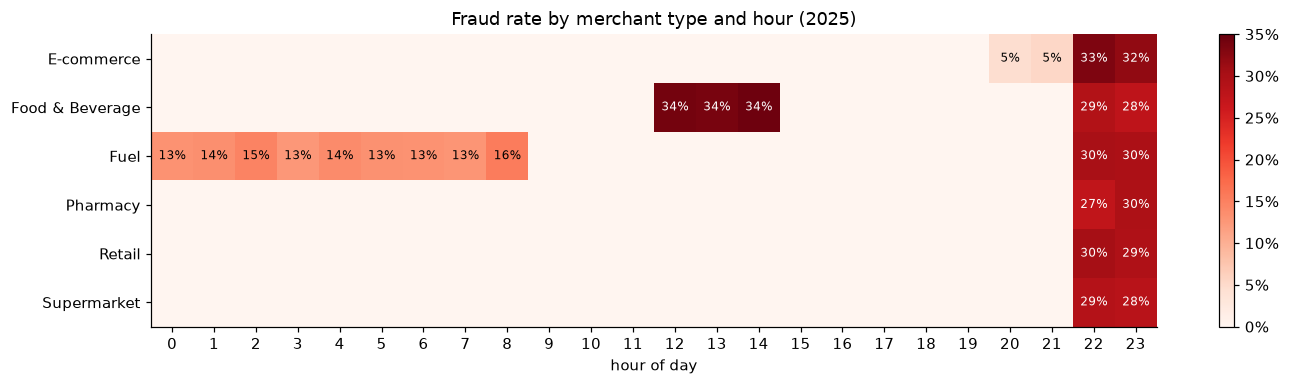

In [8]:
heat = history.pivot_table(index="tipo_estabelecimento", columns="hour", values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(figsize=(13, 3.6))
image = ax.imshow(heat.values, cmap="Reds", aspect="auto", vmin=0, vmax=0.35)
ax.set_xticks(range(24), labels=heat.columns)
ax.set_yticks(range(len(heat)), labels=heat.index)
for (row, col), rate in np.ndenumerate(heat.values):
    if rate >= 0.04:
        ax.text(col, row, f"{rate:.0%}", ha="center", va="center", fontsize=8, color="white" if rate > 0.2 else "black")
ax.set_xlabel("hour of day")
ax.set_title("Fraud rate by merchant type and hour (2025)")
fig.colorbar(image, ax=ax, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
fig.savefig(OUTPUTS / "fraud_heatmap.png", bbox_inches="tight")

In [9]:
RISK_THRESHOLD = 0.10


def risk_windows(df):
    rates = df.pivot_table(index="tipo_estabelecimento", columns="hour", values=TARGET, aggfunc="mean").stack()
    return rates[rates > RISK_THRESHOLD].index


def in_risk_window(df, windows):
    keys = pd.MultiIndex.from_arrays([df["tipo_estabelecimento"], df["hour"]])
    return keys.isin(windows)


history["risk_window"] = in_risk_window(history, risk_windows(history))
coverage = history.groupby("risk_window").agg(transactions=(TARGET, "size"), frauds=(TARGET, "sum"))
coverage["share_of_transactions"] = coverage["transactions"] / coverage["transactions"].sum()
coverage["share_of_frauds"] = coverage["frauds"] / coverage["frauds"].sum()
coverage["fraud_rate"] = coverage["frauds"] / coverage["transactions"]
coverage

,transactions,frauds,share_of_transactions,share_of_frauds,fraud_rate
risk_window,,,,,
False,447420,446,0.8546,0.0218,0.0010
True,76105,20039,0.1454,0.9782,0.2633


**Fraud is concentrated in a few time windows, each tied to a merchant type:**

- Fuel, from midnight to 8 a.m. (about 13%)
- Food & Beverage, from 12 p.m. to 2 p.m. (about 34%)
- Any merchant, from 10 p.m. to midnight (about 29%)

These windows hold about 15% of the transactions but **98% of the frauds**. Outside them, fraud is close to zero.

## 3. What drives fraud inside the risk windows

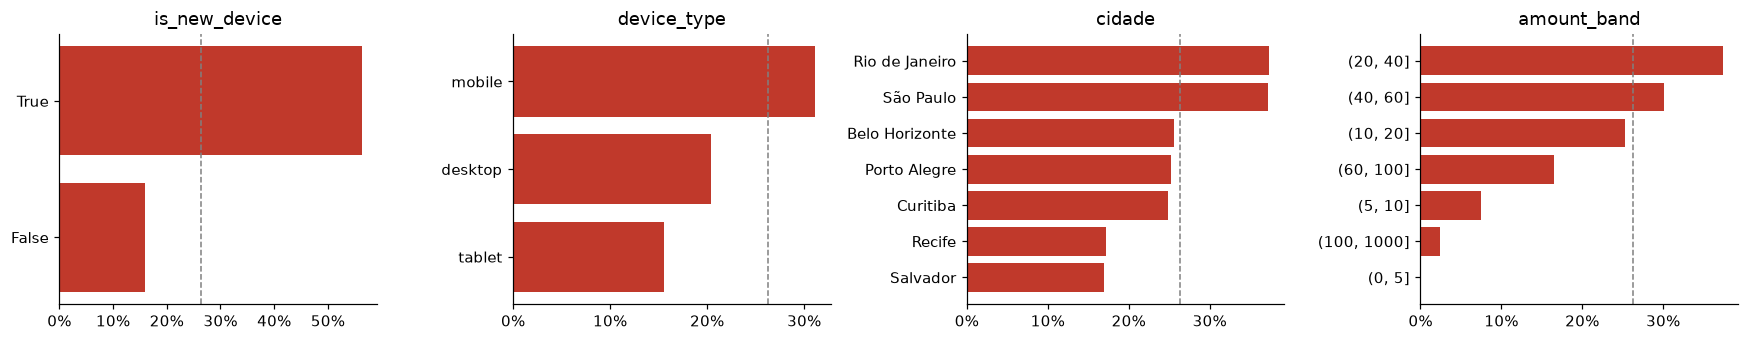

In [10]:
window = history[history["risk_window"]].copy()
window["amount_band"] = pd.cut(window["valor_transacao"], [0, 5, 10, 20, 40, 60, 100, 1000])

fraud_rate_bars(window, ["is_new_device", "device_type", "cidade", "amount_band"]);

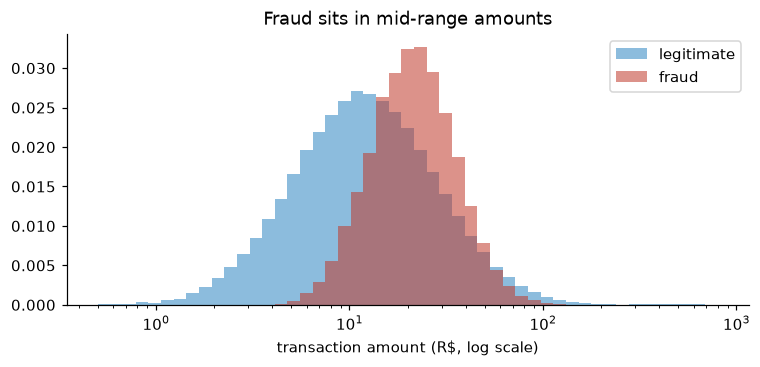

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(np.log10(0.5), np.log10(800), 50)
for label, color, name in [(0, LEGIT_COLOR, "legitimate"), (1, FRAUD_COLOR, "fraud")]:
    values = history.loc[history[TARGET] == label, "valor_transacao"]
    ax.hist(values, bins=bins, density=True, alpha=0.55, color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("transaction amount (R$, log scale)")
ax.set_title("Fraud sits in mid-range amounts")
ax.legend();

Inside the windows, the risk rises with:

- **a new device** (about 56% fraud, against 16% on a known device);
- **mobile**, and **São Paulo or Rio de Janeiro** (about 37%, against 17% in Recife and Salvador);
- **amounts between R$ 10 and R$ 60**. There is no fraud under R$ 5 or above R$ 220: fraudsters keep purchases ordinary so they do not draw attention.

In [12]:
ordered = history.sort_values("datahora_transacao")
previous_frauds = ordered.groupby("nome_cliente")[TARGET].cumsum() - ordered[TARGET]
ordered.groupby(previous_frauds.clip(upper=3))[TARGET].agg(fraud_rate="mean", transactions="size").rename_axis("client's previous frauds")

,fraud_rate,transactions
client's previous frauds,,
0,0.0387,367546
1,0.0397,121526
2,0.0421,28250
3,0.0414,6203


A client's past frauds do not change the chance of a new one, so client history adds nothing here. In real card data it usually does; this is worth checking with the fraud team before production.

## 4. What changes over time

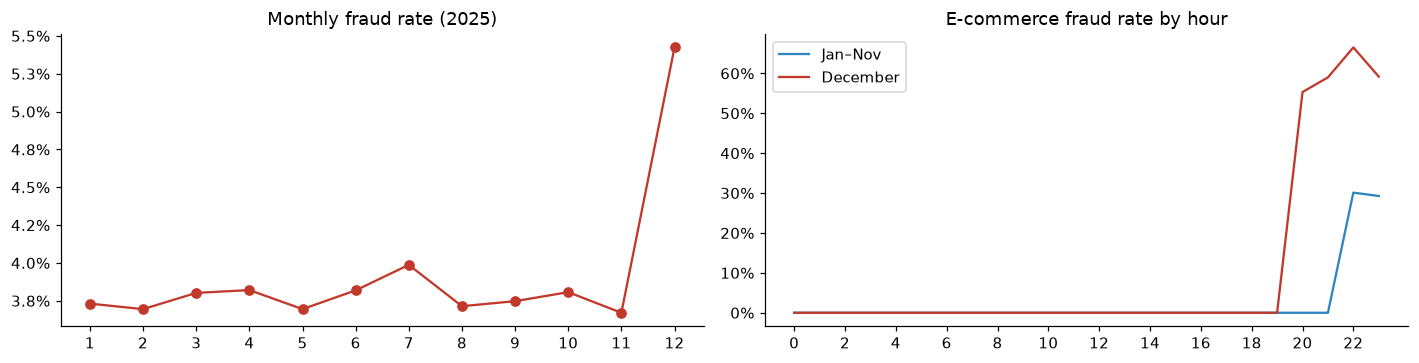

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))

monthly = history.groupby("month")[TARGET].mean()
axes[0].plot(monthly.index, monthly.values, marker="o", color=FRAUD_COLOR)
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Monthly fraud rate (2025)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))

ecommerce = history[history["tipo_estabelecimento"] == "E-commerce"]
by_hour = ecommerce.pivot_table(index="hour", columns=ecommerce["month"] == 12, values=TARGET, aggfunc="mean")
axes[1].plot(by_hour.index, by_hour[False], color=LEGIT_COLOR, label="Jan–Nov")
axes[1].plot(by_hour.index, by_hour[True], color=FRAUD_COLOR, label="December")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("E-commerce fraud rate by hour")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
fig.tight_layout()

December brings a **new pattern**: e-commerce fraud starts at 8 p.m., which never happens in the rest of the year, and doubles at 10–11 p.m. (about 60% against 30%). The monthly rate jumps from about 3.7% to 5.4%. Two consequences for the model:

- validation must follow **time** (train on earlier months, test on later ones), never a random split;
- the final model must be **retrained with December** before scoring January, and monitored for new patterns.

In [14]:
comparison = pd.DataFrame({
    "2025": [history["valor_transacao"].mean(), history["is_new_device"].mean(), (history["hour"] >= 22).mean()],
    "Jan 2026": [january["valor_transacao"].mean(), january["is_new_device"].mean(), (january["hour"] >= 22).mean()],
}, index=["mean amount (R$)", "new device share", "share after 10 p.m."])
comparison

,2025,Jan 2026
mean amount (R$),43.9629,44.1299
new device share,0.1658,0.1651
share after 10 p.m.,0.0833,0.0834


January 2026 looks like 2025 on the main inputs, so the model trained on 2025 applies to it.

**About the label.** The model can only be as good as `flag_fraude`. Before production we would confirm with the fraud team how a transaction becomes "fraud" (chargeback, customer complaint, analyst decision) and how long that takes, since late confirmations make the most recent months look cleaner than they are.

## 5. Exploration takeaways

- **Keep:** hour, merchant type, new device, device type, city, amount.
- **Drop:** `score_interno` and `temperatura_celsius` (no signal), `codigo_postal` and `nome_cliente` (identifiers), and the columns derived from others.
- **Validate by time**, and retrain with December before classifying January.
- **The bar to beat** is a simple rule: "flag every transaction inside a risk window". A model is only worth it if it does better than that.

## 6. Validation by time

The models are trained on **January to October** and judged on **November and December**, months they never saw. This is how the model will live in production: trained on the past, used on the future. It also puts the December shift inside the test, instead of hiding it in a random split.

The risk windows of the rule are learned again on the training months only, so the rule does not see the answers either.

In [15]:
train = history[history["month"] <= 10]
valid = history[history["month"] >= 11]
y_valid = valid[TARGET].to_numpy()

pd.DataFrame({
    "transactions": [len(train), len(valid)],
    "frauds": [train[TARGET].sum(), valid[TARGET].sum()],
    "fraud rate": [train[TARGET].mean(), valid[TARGET].mean()],
}, index=["train (Jan–Oct)", "validation (Nov–Dec)"])

,transactions,frauds,fraud rate
train (Jan–Oct),436034,16494,0.0378
validation (Nov–Dec),87491,3991,0.0456


## 7. Models, from simplest to most complex

Three candidates, each more complex than the last. A model only earns its complexity if it does better than the one before it.

1. **Rule:** flag every transaction inside a risk window.
2. **Logistic regression:** one weight per merchant type × hour cell, device, city and amount band. Every weight can be read.
3. **LightGBM:** gradient-boosted trees on the raw hour and amount; it finds the windows and their interactions by itself.

In [16]:
rule_score = in_risk_window(valid, risk_windows(train)).astype(float)

In [17]:
AMOUNT_BANDS = [0, 5, 10, 20, 40, 60, 100, 220, np.inf]


def logistic_inputs(df):
    return pd.DataFrame({
        "merchant_hour": df["tipo_estabelecimento"] + " " + df["hour"].astype(str),
        "device_type": df["device_type"],
        "cidade": df["cidade"],
        "amount_band": pd.cut(df["valor_transacao"], AMOUNT_BANDS).astype(str),
        "is_new_device": df["is_new_device"].astype(int),
    })


logistic = make_pipeline(
    ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore"), ["merchant_hour", "device_type", "cidade", "amount_band"])],
        remainder="passthrough",
    ),
    LogisticRegression(max_iter=2000),
)
logistic.fit(logistic_inputs(train), train[TARGET])
logistic_score = logistic.predict_proba(logistic_inputs(valid))[:, 1]

In [18]:
CATEGORICAL = ["tipo_estabelecimento", "device_type", "cidade"]
FEATURES = ["hour", "valor_transacao", "is_new_device", *CATEGORICAL]


def lightgbm_inputs(df):
    features = df[FEATURES].copy()
    features[CATEGORICAL] = features[CATEGORICAL].astype("category")
    features["is_new_device"] = features["is_new_device"].astype(int)
    return features


lightgbm = LGBMClassifier(n_estimators=400, learning_rate=0.05, min_child_samples=100, random_state=42, verbose=-1)
lightgbm.fit(lightgbm_inputs(train), train[TARGET])
lightgbm_score = lightgbm.predict_proba(lightgbm_inputs(valid))[:, 1]

### How we compare them

- **PR-AUC** summarises precision and recall over every possible cut-off. A random guess scores the fraud rate (0.05); a perfect model scores 1.
- At a chosen cut-off:
  - **precision**: of the flagged transactions, how many are fraud;
  - **recall**: of the frauds, how many are flagged;
  - **false positive rate**: of the legitimate transactions, how many are flagged by mistake. Each one is a customer bothered.

For a fair comparison, each model gets the cut-off that **catches as many frauds as the rule**. The question then becomes: at the same protection, how many legitimate customers does each one bother?

In [19]:
def operating_point(y, flagged):
    fraud = y == 1
    return {
        "flagged": flagged.mean(),
        "precision": (flagged & fraud).sum() / flagged.sum(),
        "recall": (flagged & fraud).sum() / fraud.sum(),
        "false positive rate": (flagged & ~fraud).sum() / (~fraud).sum(),
        "legitimate flagged": (flagged & ~fraud).sum(),
    }


def threshold_for_recall(y, score, recall):
    fraud_scores = np.sort(score[y == 1])[::-1]
    return fraud_scores[round(recall * len(fraud_scores)) - 1]


scores = {"rule": rule_score, "logistic regression": logistic_score, "LightGBM": lightgbm_score}
rule_recall = operating_point(y_valid, rule_score == 1)["recall"]
flags = {name: score >= threshold_for_recall(y_valid, score, rule_recall) for name, score in scores.items()}

model_comparison = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_valid, scores[name]), **operating_point(y_valid, flags[name])}
    for name in scores
}).T
model_comparison["legitimate flagged"] = model_comparison["legitimate flagged"].astype(int)
model_comparison

,PR-AUC,flagged,precision,recall,false positive rate,legitimate flagged
rule,0.2541,0.1445,0.2803,0.8882,0.1090,9100
logistic regression,0.5785,0.1375,0.2948,0.8882,0.1016,8481
LightGBM,0.6274,0.1091,0.3713,0.8882,0.0719,6002


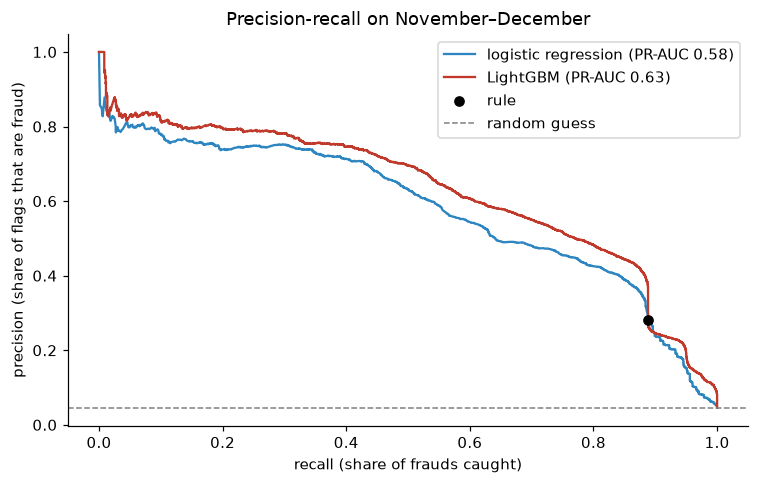

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, color in [("logistic regression", LEGIT_COLOR), ("LightGBM", FRAUD_COLOR)]:
    precision, recall, _ = precision_recall_curve(y_valid, scores[name])
    ax.plot(recall, precision, color=color, label=f"{name} (PR-AUC {model_comparison.loc[name, 'PR-AUC']:.2f})")
rule_point = model_comparison.loc["rule"]
ax.scatter(rule_point["recall"], rule_point["precision"], color="black", zorder=3, label="rule")
ax.axhline(y_valid.mean(), color="grey", linestyle="--", linewidth=1, label="random guess")
ax.set_xlabel("recall (share of frauds caught)")
ax.set_ylabel("precision (share of flags that are fraud)")
ax.set_title("Precision-recall on November–December")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUTS / "precision_recall.png", bbox_inches="tight")

### What none of them catches

In [21]:
new_pattern = (
    (valid["tipo_estabelecimento"] == "E-commerce") & (valid["month"] == 12) & valid["hour"].between(20, 21)
).to_numpy()

pd.DataFrame({
    name: {
        "frauds missed": (~flag & (y_valid == 1)).sum(),
        "of which December e-commerce, 8–10 p.m.": (~flag & (y_valid == 1) & new_pattern).sum(),
    }
    for name, flag in flags.items()
}).T

,frauds missed,"of which December e-commerce, 8–10 p.m."
rule,446,446
logistic regression,446,446
LightGBM,446,446


### Model choice

- **The rule is a single point; the models are a dial.** The rule flags 14.5% of all transactions and cannot be tuned. The models rank every transaction, so the cut-off can follow the size of the review team.
- **Logistic regression** beats the rule over most of the curve (PR-AUC 0.58 against 0.25), but at the rule's recall it bothers almost the same customers (8,481 against 9,100).
- **LightGBM** catches the same frauds as the rule and bothers **about 3,100 fewer legitimate customers in two months** (false positive rate 7.2% against 10.9%). It also has the best PR-AUC (0.63). Its extra complexity pays off, so it is the model we take forward, with explanations so it does not become a black box.
- **All three miss the same 446 frauds, and every one of them is December e-commerce between 8 and 10 p.m.**, a pattern absent from the training months. No model learns what it has never seen: the final model is retrained with December before scoring January, and fraud is monitored month by month to catch the next new pattern early.

## 8. Decision in three bands

A score does not decide anything by itself. Each transaction gets one of three actions, and each action has a cost:

- **approve**: if it is fraud, we lose the amount (chargeback);
- **send to human review**: an analyst's time. We assume the analyst gets it right;
- **block**: if it is legitimate, a customer is bothered (lost sale, support call, risk of churn).

The costs below are **assumptions to validate with the business**. Everything that follows is recalculated if they change.

In [22]:
REVIEW_COST = 3.0
BLOCKED_CUSTOMER_COST = 15.0
REVIEW_CAPACITY_PER_DAY = 150

average_fraud_loss = train.loc[train[TARGET] == 1, "valor_transacao"].mean()
print(f"Average fraud loss (Jan–Oct): R$ {average_fraud_loss:.2f}")

Average fraud loss (Jan–Oct): R$ 30.95


The cut-offs follow from the costs. For a transaction with fraud probability *p*:

- **review instead of approve** when the expected loss is larger than the review: *p* × average fraud loss > review cost;
- **block instead of review** when bothering a good customer costs less than the review: (1 − *p*) × blocked customer cost < review cost.

This only works if the score behaves like a probability. On the validation months, it does:

In [23]:
SCORE_BANDS = [0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.8, 1]

calibration = pd.DataFrame({"score": lightgbm_score, "fraud": y_valid})
calibration.groupby(pd.cut(calibration["score"], SCORE_BANDS), observed=True).agg(
    transactions=("fraud", "size"),
    mean_score=("score", "mean"),
    fraud_rate=("fraud", "mean"),
)

,transactions,mean_score,fraud_rate
score,,,
"(0.0, 0.01]",78188,0.0001,0.0057
"(0.01, 0.05]",522,0.0295,0.0326
"(0.05, 0.1]",674,0.0742,0.0846
"(0.1, 0.3]",3763,0.2080,0.2477
"(0.3, 0.5]",1668,0.3693,0.3885
"(0.5, 0.8]",2190,0.6655,0.6808
"(0.8, 1.0]",486,0.8518,0.8169


In [24]:
def cut_offs(review_cost, blocked_customer_cost):
    return review_cost / average_fraud_loss, 1 - review_cost / blocked_customer_cost


def decide(score, review_cost, blocked_customer_cost):
    review_from, block_from = cut_offs(review_cost, blocked_customer_cost)
    return np.select([score >= block_from, score >= review_from], ["block", "review"], "approve")


def outcome_for(score, review_cost, blocked_customer_cost):
    return pd.DataFrame({
        "decision": decide(score, review_cost, blocked_customer_cost),
        "fraud": y_valid,
        "fraud_amount": valid["valor_transacao"].to_numpy() * y_valid,
    })


days = valid["datahora_transacao"].dt.date.nunique()
review_from, block_from = cut_offs(REVIEW_COST, BLOCKED_CUSTOMER_COST)
outcome = outcome_for(lightgbm_score, REVIEW_COST, BLOCKED_CUSTOMER_COST)

bands = outcome.groupby("decision").agg(
    transactions=("fraud", "size"),
    frauds=("fraud", "sum"),
    fraud_amount=("fraud_amount", "sum"),
).reindex(["approve", "review", "block"])
bands["legitimate"] = bands["transactions"] - bands["frauds"]
bands["per day"] = bands["transactions"] / days
bands["share of frauds"] = bands["frauds"] / bands["frauds"].sum()

print(f"Review from score {review_from:.2f}, block from score {block_from:.2f}")
bands.style.format({"fraud_amount": "R$ {:,.0f}", "per day": "{:,.0f}", "share of frauds": "{:.0%}"})

Review from score 0.10, block from score 0.80


,transactions,frauds,fraud_amount,legitimate,per day,share of frauds
decision,,,,,,
approve,79347,518,"R$ 16,287",78829,"1,301",13%
review,7658,3076,"R$ 93,081",4582,126,77%
block,486,397,"R$ 12,294",89,8,10%


In [25]:
reviews_per_day = pd.Series(outcome["decision"].eq("review").to_numpy()).groupby(valid["datahora_transacao"].dt.date.to_numpy()).sum()
print(f"Reviews per day: average {reviews_per_day.mean():.0f}, busiest day {reviews_per_day.max()}, capacity {REVIEW_CAPACITY_PER_DAY}")
print(f"Days over capacity: {(reviews_per_day > REVIEW_CAPACITY_PER_DAY).sum()} of {days}")

Reviews per day: average 126, busiest day 136, capacity 150
Days over capacity: 0 of 61


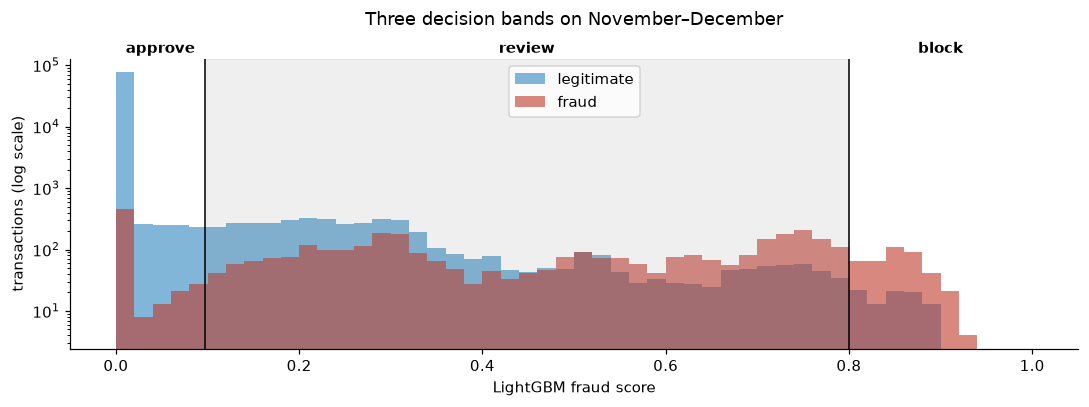

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.linspace(0, 1, 51)
for label, color, name in [(0, LEGIT_COLOR, "legitimate"), (1, FRAUD_COLOR, "fraud")]:
    ax.hist(lightgbm_score[y_valid == label], bins=bins, alpha=0.6, color=color, label=name)
ax.set_yscale("log")
ax.axvspan(review_from, block_from, color="grey", alpha=0.12)
for cut in (review_from, block_from):
    ax.axvline(cut, color="black", linewidth=1)
for x, name in [(review_from / 2, "approve"), ((review_from + block_from) / 2, "review"), ((block_from + 1) / 2, "block")]:
    ax.text(x, 1.02, name, transform=ax.get_xaxis_transform(), ha="center", fontsize=10, fontweight="bold")
ax.set_xlabel("LightGBM fraud score")
ax.set_ylabel("transactions (log scale)")
ax.set_title("Three decision bands on November–December", pad=22)
ax.legend(loc="upper center")
fig.tight_layout()
fig.savefig(OUTPUTS / "decision_bands.png", bbox_inches="tight")

In [27]:
def costs(outcome, review_cost, blocked_customer_cost):
    approved_fraud = outcome.loc[outcome["decision"] == "approve", "fraud_amount"].sum()
    reviews = (outcome["decision"] == "review").sum() * review_cost
    blocked_customers = ((outcome["decision"] == "block") & (outcome["fraud"] == 0)).sum() * blocked_customer_cost
    return {
        "fraud approved": approved_fraud,
        "reviews": reviews,
        "customers blocked": blocked_customers,
        "total": approved_fraud + reviews + blocked_customers,
    }


pd.DataFrame({
    "approve everything": {"fraud approved": outcome["fraud_amount"].sum(), "reviews": 0, "customers blocked": 0, "total": outcome["fraud_amount"].sum()},
    "three bands": costs(outcome, REVIEW_COST, BLOCKED_CUSTOMER_COST),
}).T.style.format("R$ {:,.0f}")

,fraud approved,reviews,customers blocked,total
approve everything,"R$ 121,662",R$ 0,R$ 0,"R$ 121,662"
three bands,"R$ 16,287","R$ 22,974","R$ 1,335","R$ 40,596"


**How much the decision depends on the assumptions.** The same model under other costs:

In [28]:
scenarios = []
for review_cost in [2, 3, 5]:
    for blocked_customer_cost in [10, 15, 30]:
        scenario = outcome_for(lightgbm_score, review_cost, blocked_customer_cost)
        decisions = scenario["decision"].value_counts()
        scenarios.append({
            "review cost": review_cost,
            "blocked customer cost": blocked_customer_cost,
            "review from": cut_offs(review_cost, blocked_customer_cost)[0],
            "block from": cut_offs(review_cost, blocked_customer_cost)[1],
            "reviews per day": decisions.get("review", 0) / days,
            "blocks per day": decisions.get("block", 0) / days,
            "frauds stopped": scenario.loc[scenario["decision"] != "approve", "fraud"].sum() / scenario["fraud"].sum(),
            "total cost (R$)": costs(scenario, review_cost, blocked_customer_cost)["total"],
        })
pd.DataFrame(scenarios).set_index(["review cost", "blocked customer cost"]).style.format({
    "review from": "{:.2f}",
    "block from": "{:.2f}",
    "reviews per day": "{:.0f}",
    "blocks per day": "{:.0f}",
    "frauds stopped": "{:.0%}",
    "total cost (R$)": "R$ {:,.0f}",
})

### What the three bands deliver

- **Review from score 0.10, block from 0.80.** Each day, about 1,300 transactions are approved automatically, **126 go to an analyst** and **8 are blocked**. The busiest day had 136 reviews, within the team's assumed capacity of 150.
- **87% of the frauds are stopped**: 77% in review and 10% blocked. Only 89 legitimate customers were blocked in two months, about 1.5 a day.
- Of the 518 frauds approved, **446 are the December e-commerce pattern** the model never saw in training, the gap that retraining closes.
- **Cost over the two months drops from R$ 121.7k to R$ 40.6k**, two thirds less than approving everything.
- **The decision holds when the assumptions change.** Across all nine scenarios the model stops 83–88% of the frauds and the queue stays between 73 and 141 a day. The cost of a review moves the total the most; the cost of a blocked customer only moves transactions between review and block.

## 9. Explainability

A fraud team will not trust, and a regulator will not accept, a score nobody can explain. LightGBM gives, for each transaction, how much each input pushed the score up or down (SHAP values). The pushes are on the log-odds scale: positive means "more likely fraud", and they add up to the final score.

We use them three ways: what matters overall, how risk moves with hour and amount, and the reasons an analyst sees next to each transaction in the review queue.

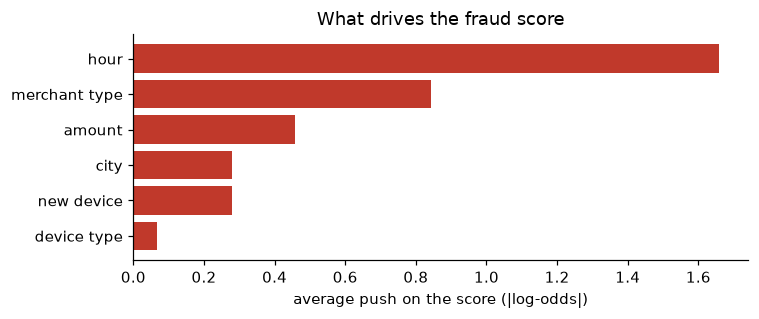

In [29]:
FEATURE_LABELS = {
    "hour": "hour",
    "valor_transacao": "amount",
    "is_new_device": "new device",
    "tipo_estabelecimento": "merchant type",
    "device_type": "device type",
    "cidade": "city",
}

contributions = pd.DataFrame(
    lightgbm.predict(lightgbm_inputs(valid), pred_contrib=True)[:, :-1],
    columns=FEATURES,
    index=valid.index,
)

importance = contributions.abs().mean().rename(FEATURE_LABELS).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(importance.index, importance.values, color=FRAUD_COLOR)
ax.set_xlabel("average push on the score (|log-odds|)")
ax.set_title("What drives the fraud score")
fig.tight_layout()
fig.savefig(OUTPUTS / "feature_importance.png", bbox_inches="tight")

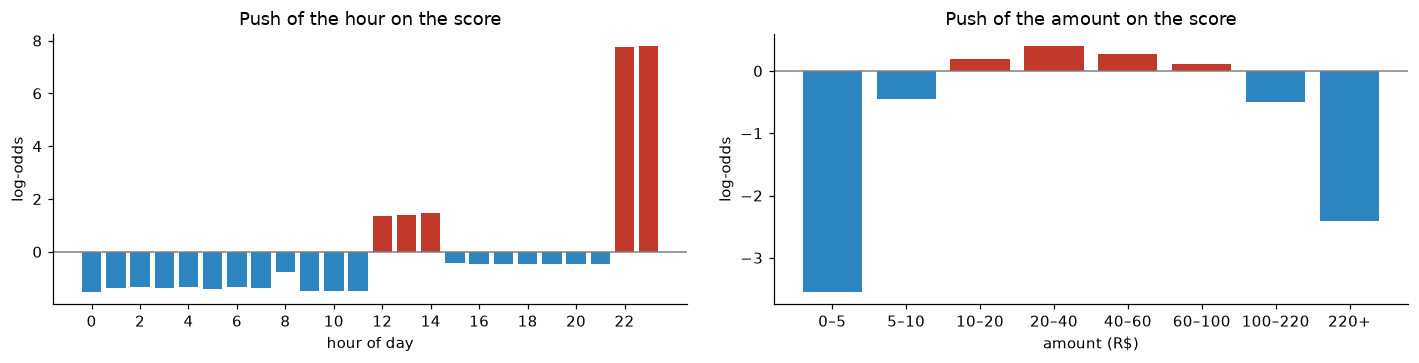

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))

by_hour = contributions["hour"].groupby(valid["hour"]).mean()
axes[0].bar(by_hour.index, by_hour.values, color=np.where(by_hour > 0, FRAUD_COLOR, LEGIT_COLOR))
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("hour of day")
axes[0].set_title("Push of the hour on the score")

amount_band = pd.cut(valid["valor_transacao"], AMOUNT_BANDS)
by_amount = contributions["valor_transacao"].groupby(amount_band, observed=True).mean()
labels = [f"{band.left:.0f}–{band.right:.0f}" if np.isfinite(band.right) else f"{band.left:.0f}+" for band in by_amount.index]
axes[1].bar(labels, by_amount.values, color=np.where(by_amount > 0, FRAUD_COLOR, LEGIT_COLOR))
axes[1].set_xlabel("amount (R$)")
axes[1].set_title("Push of the amount on the score")

for ax in axes:
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_ylabel("log-odds")
fig.tight_layout()

### Reasons in the review queue

Each flagged transaction reaches the analyst with its score and the three inputs that weighed the most:

In [31]:
def describe(feature, row):
    value = row[feature]
    if feature == "hour":
        return f"{value}h"
    if feature == "valor_transacao":
        return f"R$ {value:.2f}"
    if feature == "is_new_device":
        return "new device" if value else "known device"
    return str(value)


def reasons(index, top=3):
    pushes = contributions.loc[index].sort_values(key=abs, ascending=False).head(top)
    row = valid.loc[index]
    return "; ".join(f"{describe(feature, row)} ({push:+.1f})" for feature, push in pushes.items())


queue = valid.assign(score=lightgbm_score, decision=outcome["decision"].to_numpy(), fraud=y_valid)
examples = queue.groupby("decision").sample(3, random_state=7).sort_values("score", ascending=False)
examples["top reasons"] = [reasons(index) for index in examples.index]
examples[["score", "decision", "fraud", "top reasons"]].style.format({"score": "{:.2f}"})

,score,decision,fraud,top reasons
499878,0.89,block,0,12h (+4.4); Food & Beverage (+4.2); new device (+1.2)
507191,0.89,block,1,14h (+4.4); Food & Beverage (+4.1); new device (+1.2)
479933,0.86,block,1,Food & Beverage (+4.1); 14h (+4.0); new device (+1.2)
437390,0.33,review,1,22h (+7.4); R$ 27.19 (+0.7); Food & Beverage (+0.7)
466087,0.28,review,0,22h (+7.9); R$ 17.38 (+0.5); Food & Beverage (+0.5)
520592,0.17,review,1,22h (+8.0); R$ 17.37 (+0.5); known device (-0.3)
476958,0.00,approve,0,Supermarket (-1.1); 12h (+0.8); R$ 21.02 (+0.3)
475227,0.00,approve,0,7h (-1.4); E-commerce (-0.8); Rio de Janeiro (+0.4)
484910,0.00,approve,0,R$ 1.84 (-3.7); 1h (-1.2); Supermarket (-0.2)


### What the model learned

- **The model rediscovered the risk windows on its own.** Hour and merchant type are the two strongest inputs. On average, 10–11 p.m. pushes the score up by about +8 and noon to 2 p.m. by about +1.4 (over +4 for Food & Beverage); every other hour pushes it down.
- The night window at fuel stations does not show in the hour chart because that chart averages all merchant types. It enters through the merchant type: a fuel transaction at night gets about +3.2 from it, against +1.2 during the day.
- **Amount works as a filter**: under R$ 5 and above R$ 220 the score drops sharply (−3.5 and −2.4), the same "ordinary purchase" pattern seen in the exploration.
- **A new device weighs less than in the exploration** because, on average, it is overshadowed by hour and merchant type. Inside a risk window it still adds about +1.2, often enough to tip a transaction from review to block.
- **The analyst sees why.** In the examples, the blocked legitimate purchase (Food & Beverage at noon, on a new device) looks exactly like the frauds next to it. Showing the reasons lets the analyst check the one thing the model cannot see, such as a customer who just changed phones, and every decision can be explained to the customer.

## 10. Impact in numbers

Four ways to run the same two months (November and December), with the same cost assumptions:

1. **approve everything**: no control;
2. **rule, review every window**: every transaction in a risk window goes to an analyst;
3. **rule, team capacity**: the same rule, but the team reviews at most 150 a day, picked at random among the window transactions (the rule cannot say which ones matter more);
4. **LightGBM, three bands**: the proposal.

In [32]:
dates = valid["datahora_transacao"].dt.date.to_numpy()
in_window = rule_score == 1
rng = np.random.default_rng(42)


def within_capacity(candidates):
    kept = np.zeros_like(candidates)
    for day in np.unique(dates):
        today = np.flatnonzero(candidates & (dates == day))
        kept[rng.choice(today, size=min(len(today), REVIEW_CAPACITY_PER_DAY), replace=False)] = True
    return kept


def as_outcome(decision):
    return pd.DataFrame({
        "decision": decision,
        "fraud": y_valid,
        "fraud_amount": valid["valor_transacao"].to_numpy() * y_valid,
    })


def impact(decision):
    result = as_outcome(decision)
    fraud = result["fraud"] == 1
    stopped = result["decision"] != "approve"
    return {
        "frauds stopped": (stopped & fraud).sum() / fraud.sum(),
        "fraud stopped (R$)": result.loc[stopped, "fraud_amount"].sum(),
        "fraud lost (R$)": result.loc[~stopped, "fraud_amount"].sum(),
        "reviews per day": (result["decision"] == "review").sum() / days,
        "legitimate reviewed": ((result["decision"] == "review") & ~fraud).sum(),
        "legitimate blocked": ((result["decision"] == "block") & ~fraud).sum(),
        "total cost (R$)": costs(result, REVIEW_COST, BLOCKED_CUSTOMER_COST)["total"],
    }


strategies = {
    "approve everything": np.full(len(valid), "approve"),
    "rule, review every window": np.where(in_window, "review", "approve"),
    "rule, team capacity": np.where(within_capacity(in_window), "review", "approve"),
    "LightGBM, three bands": outcome["decision"].to_numpy(),
}

impact_table = pd.DataFrame({name: impact(decision) for name, decision in strategies.items()}).T
impact_table.style.format({
    "frauds stopped": "{:.0%}",
    "fraud stopped (R$)": "R$ {:,.0f}",
    "fraud lost (R$)": "R$ {:,.0f}",
    "reviews per day": "{:.0f}",
    "legitimate reviewed": "{:,.0f}",
    "legitimate blocked": "{:,.0f}",
    "total cost (R$)": "R$ {:,.0f}",
})

,frauds stopped,fraud stopped (R$),fraud lost (R$),reviews per day,legitimate reviewed,legitimate blocked,total cost (R$)
approve everything,0%,R$ 0,"R$ 121,662",0,0,0,"R$ 121,662"
"rule, review every window",89%,"R$ 108,374","R$ 13,288",207,"9,100",0,"R$ 51,223"
"rule, team capacity",64%,"R$ 77,640","R$ 44,022",150,"6,606",0,"R$ 71,472"
"LightGBM, three bands",87%,"R$ 105,375","R$ 16,287",126,"4,582",89,"R$ 40,596"


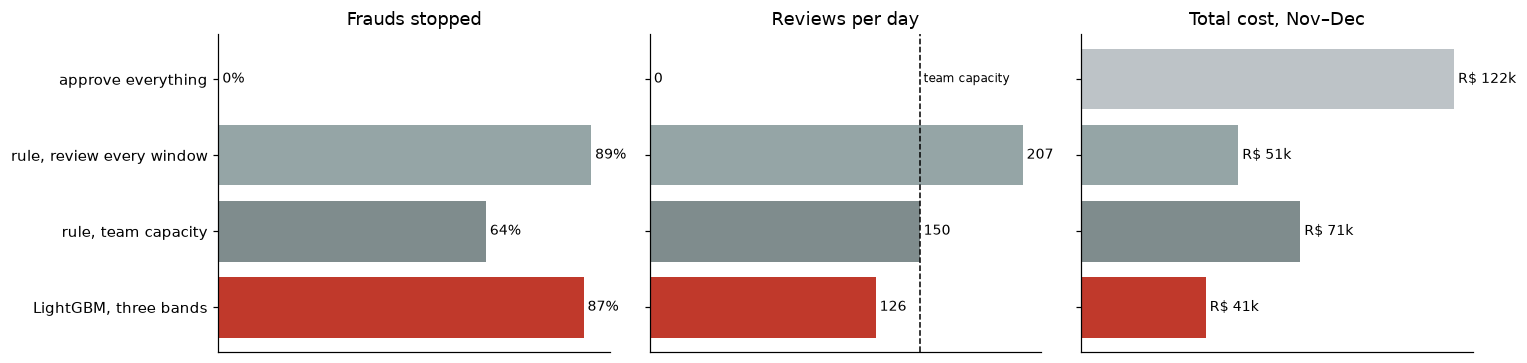

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
colors = ["#bdc3c7", "#95a5a6", "#7f8c8d", FRAUD_COLOR]
panels = [
    ("frauds stopped", "Frauds stopped", lambda v: f"{v:.0%}"),
    ("reviews per day", "Reviews per day", lambda v: f"{v:.0f}"),
    ("total cost (R$)", "Total cost, Nov–Dec", lambda v: f"R$ {v / 1000:.0f}k"),
]
for ax, (column, title, label) in zip(axes, panels):
    values = impact_table[column]
    ax.barh(values.index, values.values, color=colors)
    for y, value in enumerate(values.values):
        ax.text(value, y, f" {label(value)}", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xticks([])
    ax.invert_yaxis()
axes[1].axvline(REVIEW_CAPACITY_PER_DAY, color="black", linestyle="--", linewidth=1)
axes[1].text(REVIEW_CAPACITY_PER_DAY, 0, " team capacity", va="center", fontsize=8)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
fig.savefig(OUTPUTS / "impact.png", bbox_inches="tight")

### What changes for the business

- **Against the rule with the same team**, the model stops **87% of the frauds instead of 64%**. Fraud losses fall from R$ 44.0k to R$ 16.3k in two months, **about R$ 14k less a month**, using 126 of the 150 daily reviews instead of all of them.
- **Against the rule with unlimited reviews**, the model stops almost the same share of frauds (87% against 89%) with **40% fewer reviews** (126 a day against 207, which the team cannot handle). Legitimate customers sent to review or blocked drop by half, from 9,100 to about 4,700.
- **The total cost is the lowest of the four**: R$ 40.6k, against R$ 51.2k for the full rule, R$ 71.5k for the rule within capacity and R$ 121.7k with no control.
- The price is **89 legitimate customers blocked in two months**, about 1.5 a day, each with the reasons shown in section 9 to handle the complaint.

These figures come from November and December, with December's new pattern missed. A model retrained with December should do better in January; the monitoring plan checks that.